# Can Unsupervised Learning Discover Stable Equity Themes?

## A Multi-Horizon Clustering Study of U.S. Equities

### Abstract

This study examines whether unsupervised machine learning can identify stable and economically meaningful groups of U.S. equities using daily return co-movement alone.

Approximately five years of daily price data are collected for primary share classes with a current market capitalisation above $300 million and a share price above $1. After missing-data treatment, returns are standardised and compressed using Principal Component Analysis. K-Means clustering is then applied over one, three, and five-year windows. Robustness is evaluated across different PCA dimensions, random seeds, time horizons, and alternative clustering algorithms. A consensus-clustering framework is subsequently used to identify stable core members and construct a hierarchical equity-theme classification.

The results show that return-based clustering recovers several recognisable economic groups, including regional banks, REITs, energy companies, shipping firms, biotechnology companies, miners, and semiconductor businesses. However, silhouette scores remain modest, indicating substantial overlap between groups. Cluster agreement is higher between the three and five year windows than between the one and five year windows, suggesting that recent relationships can differ materially from longer-term structure.

The final hierarchical procedure produces 224 return-based themes across 2,927 stocks. These findings support the use of unsupervised learning as an exploratory equity-classification tool, but not as evidence of permanent industry relationships or a deployable investment strategy.

### Research Question

Can unsupervised learning identify equity groups that are economically interpretable and stable across different time horizons and modelling assumptions?

### Hypotheses

1. Daily return co-movement contains enough structure to recover recognisable economic groups.

2. Meaningful clusters should remain reasonably stable across PCA dimensions and random initialisations.

3. Longer estimation windows should produce more stable group relationships than shorter windows.

4. Consensus clustering should distinguish persistent core members from ambiguous boundary stocks.

### Study Design
The study follows seven stages:
1. Construct a liquid equity universe using current price, market-capitalisation, and share-class filters.

2. Produce standardised daily-return matrices over one, three, and five year windows.

3. Reduce dimensionality with PCA and estimate baseline K-Means clusters.

4. Test sensitivity to PCA dimensions, random seeds, and time horizons.

5. Estimate pairwise co-clustering probabilities through repeated consensus clustering.

6. Compare K-Means with Ward, HDBSCAN, and consensus-based hierarchical clustering.

7. Refine broad one-year groups into smaller return-based themes.

### 1. Experimental Configuration

|Parameter | Value | Purpose |
|--|--|--|
|Historical observations | 1259 Trading days| Approximately five years of data |
|Minimum market capitalisation | $300 million | Excludes very small companies |
|Minimum share price| $1| Excludes low-prices securities|
|Maximum missing rate| 5% | Remove incomplete price histories|
|Analysis windows| 1, 3 and 5 years| Tests time-horizon stability|
|Return clipping | +- 5 standard deviations | Limits the influence of extreme returns|
|PCA components| 20 | Reduce noise and dimensionality|
|K-Means clusters| 20 | Provides a common comparison across windows|
|Minimum final theme size| 3 stocks | Avoids extremely small themes|
|Minimum theme correlation | 0.40 | Requires reasonable internal coherence|

The PCA and cluster parameters are treated as modelling choices rather than optimised trading parameters. Their sensitivity is examined later in the study.

In [1]:
import pandas as pd
import N_DB


DAYS= 1261
MIN_MCAP = 0.3
MIN_PRICE = 1


### 2. Data and Universe Construction

The dataset contains daily closing prices for primary share classes available in the local equity database.

The initial universe is restricted to securities that satisfy the following current filters:

- Market capitalisation of at least $300 million

- Share price of at least $1

- Positive historical closing prices

- Primary share class status

The retrieved sample contains approximately 3,042 symbols between October 2021 and October 2026.

The analysis uses current market capitalisation and security classifications. Therefore, the sample is designed to classify currently investable securities rather than reproduce a fully point-in-time historical universe.

In [2]:
px = N_DB.query("""
        WITH d AS (SELECT DISTINCT date FROM bars_daily
                    ORDER BY date DESC LIMIT :days)
        SELECT b.symbol, b.date, b.close
        FROM bars_daily b
        JOIN d ON b.date = d.date
        JOIN mv_metrics m ON m.symbol = b.symbol
        WHERE m.is_primary_class
                AND m.market_cap >= :mc * 1e9
                AND m.close >= :minp
                AND b.close > 0
        ORDER BY b.symbol, b.date
""", days=DAYS, mc=MIN_MCAP, minp=MIN_PRICE)

px['close'] = px['close'].astype(float)
# px.to_pickle("price_5y.pkl")

In [3]:
print(f"{len(px):,} rows / {px['symbol'].nunique():,} symbols")
print(f"Date: {px['date'].min()} to {px['date'].max()}")
print(f"Trade days: {px['date'].nunique():,}")


3,537,911 rows / 3,042 symbols
Date: 2021-10-13 to 2026-10-16
Trade days: 1,259


The price data are converted from long format into a date-by-symbol matrix. Rows represent trading dates, columns represent stocks, and values contain daily closing prices.

This representation allows missing observations, return histories, correlations, and stock-level features to be calculated consistently across the full universe.

In [4]:
wide = px.pivot(index='date', columns='symbol', values='close').sort_index()
print(wide.shape)
wide.iloc[-5:, :5]

(1259, 3042)


symbol,A,AA,AADX,AAL,AAMI
date,,,,,
2026-10-12,171.33,41.67,10.77,12.62,92.63
2026-10-13,171.60,41.49,10.42,12.50,91.58
2026-10-14,174.00,40.08,11.02,11.79,91.10
2026-10-15,175.55,40.42,11.35,12.28,92.81
2026-10-16,172.97,41.45,11.37,11.88,92.16


### 3. Return Construction and Missing-Data Treatment

For each analysis window, securities with more than 5% missing observations are removed. Remaining gaps are forward-filled before daily percentage returns are calculated.

Forward-filling may create artificial zero returns during missing periods. The missing-data threshold reduces, but does not eliminate, this limitation.

In [5]:
def clean_data(wide, days, max_missing= 0.05):
    w = wide.iloc[-(days+1):]
    miss = w.isna().mean()
    w = w.loc[:, miss <= max_missing]
    w = w.ffill()
    w = w.dropna(axis= 1)
    rets = w.pct_change().iloc[1:]

    return rets

In [6]:
WINDOWS = {
    "1y": 252,
    "3y": 756,
    "5y": 1260
}

rets = {name: clean_data(wide, d) for name, d in WINDOWS.items()}

for name, r in rets.items():
    print(f"{name}: {r.shape[0]:,} days x {r.shape[1]:,} symbols")

common = sorted(set.intersection(*[set(r.columns) for r in rets.values()]))
rets = {name: r[common] for name, r in rets.items()}
print(f"\n 3 windows have {len(common):,} symbols")

1y: 252 days x 2,927 symbols
3y: 756 days x 2,754 symbols
5y: 1,258 days x 2,604 symbols

 3 windows have 2,602 symbols


### 4. Return Standardisation and Dimensionality Reduction

This transformation prevents highly volatile stocks from dominating the distance calculation. Standardised returns are clipped at +-5 to reduce the influence of isolated extreme observations. The matrix is then transposed so that each row represents one stock and each column represents one trading day.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

def standardise(r, clip= 5):
    z = (r - r.mean()) / r.std()
    z = z.clip(-clip, clip)
    return z.T

X = {name: standardise(r) for name, r in rets.items()}

for name, x in X.items():
    print(f"{name}: {x.shape}, missing: {x.isna().sum().sum()}")

1y: (2602, 252), missing: 0
3y: (2602, 756), missing: 0
5y: (2602, 1258), missing: 0


PCA is applied to compress the return histories into a smaller set of common components. This reduces noise and computational cost before clustering.
The cumulative explained-variance curve is inspected rather than selecting a component count solely from a fixed variance target.

1y: PC1 = 8.6%,Top 20 = 40.8%
3y: PC1 = 5.8%,Top 20 = 31.8%
5y: PC1 = 5.4%,Top 20 = 30.2%


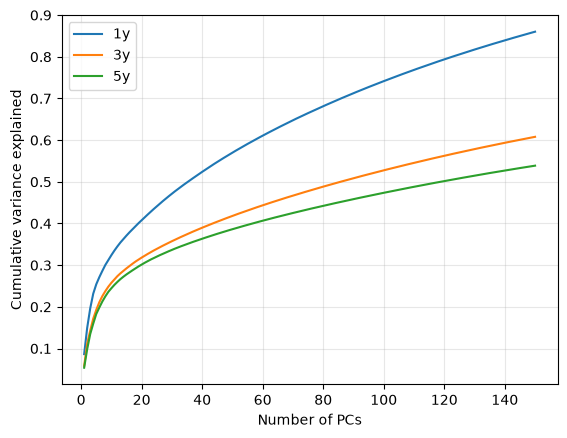

In [8]:
for name, n in X.items():
    pca = PCA(n_components= 150).fit(n)
    cum = pca.explained_variance_ratio_.cumsum()
    plt.plot(range(1, 151),cum, label= name)
    print(f"{name}: PC1 = {pca.explained_variance_ratio_[0]:.1%},"
          f"Top 20 = {cum[19]:.1%}")

plt.xlabel("Number of PCs")
plt.ylabel("Cumulative variance explained")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The first 20 principal components explain 40.8%, 31.8%, and 30.2% of total variation in the one, three, and five year windows respectively. The lower concentration over longer windows suggests that long-term equity relationships contain more dimensions than recent market behaviour.

A shuffled-data comparison is used as an approximate noise benchmark. Shuffling each stock's observations preserves its marginal return distribution while destroying aligned cross-stock relationships.

1y: 31 main higher than noise
3y: 61 main higher than noise
5y: 66 main higher than noise


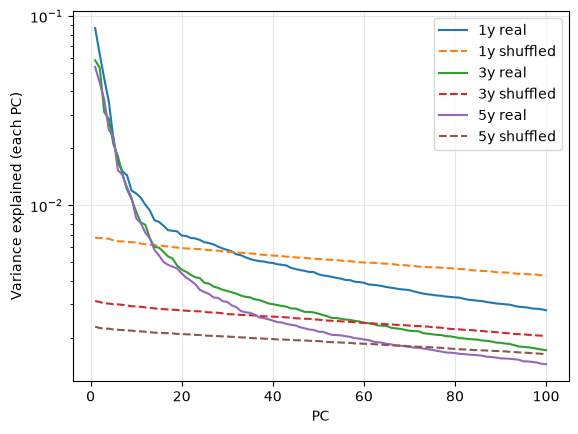

In [9]:
rng = np.random.default_rng(42)
N_MAX = 100

for name, n in X.items():
    real = PCA(n_components=N_MAX).fit(n).explained_variance_ratio_

    shuffled = rng.permuted(n.values, axis= 1)
    noise = PCA(n_components=N_MAX).fit(shuffled).explained_variance_ratio_

    n_signal = int((real > noise).sum())
    print(f"{name}: {n_signal} main higher than noise")

    plt.plot(range(1, N_MAX + 1), real, label=f"{name} real")
    plt.plot(range(1, N_MAX + 1), noise, "--", label=f"{name} shuffled")

plt.yscale("log")
plt.xlabel("PC")
plt.ylabel("Variance explained (each PC)")
plt.legend()
plt.grid(alpha= 0.3)
plt.show()

The shuffled comparison identifies 31, 61, and 66 components above the noise baseline for the one, three, and five year windows respectively.

Although this test suggests that more than 20 components may contain information, 20 components are retained to provide a consistent and relatively parsimonious representation. The robustness analysis later tests whether this choice materially determines the results.

In [10]:
N_PC = 20
Z = {}

for name, n in X.items():
    pca = PCA(n_components= N_PC, random_state= 42)
    Z[name] = pd.DataFrame(pca.fit_transform(n), index= n.index)
    print(f"{name}: {Z[name].shape}, left= {pca.explained_variance_ratio_.sum():.1%} changes")

1y: (2602, 20), left= 40.8% changes
3y: (2602, 20), left= 31.8% changes
5y: (2602, 20), left= 30.1% changes


### 5. Baseline K-Means Clustering

K-Means is fitted to the first 20 principal components for each time window. Candidate cluster counts from 4 to 30 are compared using the silhouette score.

A higher silhouette score indicates that observations are closer to members of their assigned cluster than to members of neighbouring clusters. The measure is used as a diagnostic rather than an automatic rule because statistical separation and economic interpretability may favour different resolutions.

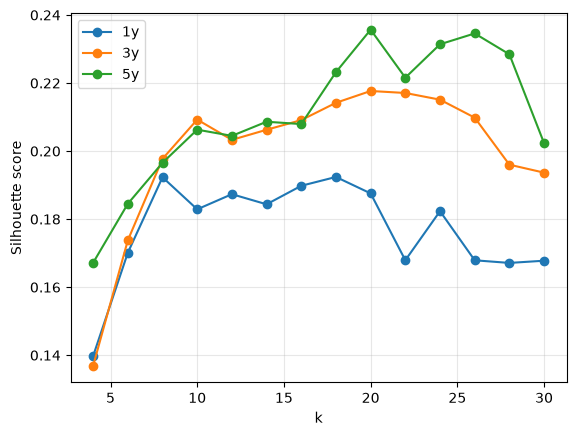

,1y,3y,5y
4,0.140,0.137,0.167
6,0.170,0.174,0.185
8,0.192,0.198,0.197
10,0.183,0.209,0.206
12,0.187,0.203,0.204
14,0.184,0.206,0.209
16,0.190,0.209,0.208
18,0.192,0.214,0.223
20,0.188,0.218,0.236
22,0.168,0.217,0.222


In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_RANGE = range(4, 31, 2)
scores = {}

for name, z in Z.items():
    s = []
    for k in K_RANGE:
        km = KMeans(n_clusters= k, n_init=10, random_state= 42)
        labels = km.fit_predict(z)
        s.append(silhouette_score(z, labels))
    scores[name] = s
    plt.plot(list(K_RANGE), s, "o-" ,label= name)

plt.xlabel("k")
plt.ylabel("Silhouette score")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

pd.DataFrame(scores, index= list(K_RANGE)).round(3)

The maximum observed silhouette scores are approximately 0.192 at $K=8$ or $K=18$ for the one-year window, 0.218 at $K=20$ for the three-year window, and 0.236 at $K=20$ for the five-year window.

Because the preferred resolution differs across windows, a common value of $K=20$ is selected for cross-window comparison. The modest scores indicate that equity relationships overlap rather than form perfectly separated categories. The clusters should therefore be interpreted as approximate return-based groups rather than definitive classifications.

In [12]:
K= 20 
labels = {}

for name, z in Z.items():
    km = KMeans(n_clusters= K, n_init=10, random_state= 42)
    labels[name] = pd.Series(km.fit_predict(z), index= z.index, name= "cluster")
    sizes = labels[name].value_counts().sort_values(ascending= False)
    print(f"{name}: largest cluster symbol-> {sizes.iloc[0]}, smallest cluster symbol-> {sizes.iloc[-1]}")

1y: largest cluster symbol-> 276, smallest cluster symbol-> 25
3y: largest cluster symbol-> 333, smallest cluster symbol-> 25
5y: largest cluster symbol-> 286, smallest cluster symbol-> 27


### 6. Parameter and Random-Seed Robustness

The baseline assignments are re-estimated using between 10 and 50 PCA components. The models are also fitted from multiple random initialisations.

Agreement is measured using the Adjusted Rand Index (ARI), which corrects for agreement expected by chance. An ARI of 1 indicates identical partitions, while a value near zero indicates little more agreement than random assignment.

In [13]:
from sklearn.metrics import adjusted_rand_score

def run_kmeans(n, n_pc, k=20):
    z = PCA(n_components=n_pc, random_state= 42).fit_transform(n)
    return KMeans(n_clusters=k, n_init=10, random_state= 42).fit_predict(z)

for name, n in X.items():
    for n_pc in [10, 25, 30, 40, 50]:
        lab = run_kmeans(n, n_pc)
        ari = adjusted_rand_score(labels[name], lab)
        print(f"{name} N_PC= {n_pc:>2} vs 20: ARI = {ari:.3f}")

1y N_PC= 10 vs 20: ARI = 0.585
1y N_PC= 25 vs 20: ARI = 0.673
1y N_PC= 30 vs 20: ARI = 0.677
1y N_PC= 40 vs 20: ARI = 0.806
1y N_PC= 50 vs 20: ARI = 0.713
3y N_PC= 10 vs 20: ARI = 0.579
3y N_PC= 25 vs 20: ARI = 0.636
3y N_PC= 30 vs 20: ARI = 0.632
3y N_PC= 40 vs 20: ARI = 0.652
3y N_PC= 50 vs 20: ARI = 0.677
5y N_PC= 10 vs 20: ARI = 0.587
5y N_PC= 25 vs 20: ARI = 0.655
5y N_PC= 30 vs 20: ARI = 0.686
5y N_PC= 40 vs 20: ARI = 0.630
5y N_PC= 50 vs 20: ARI = 0.698


In [14]:
for name, z in Z.items():
    aris = []
    for seed in range(1, 6):
        lab = KMeans(n_clusters=20, n_init=10, random_state= seed).fit_predict(z)
        aris.append(adjusted_rand_score(labels[name], lab))
    print(f"{name}: {np.round(aris, 3)} average: {np.mean(aris):.3f}")

1y: [0.715 0.704 0.695 0.702 0.733] average: 0.710
3y: [0.805 0.827 0.711 0.78  0.882] average: 0.801
5y: [0.673 0.615 0.71  0.645 0.701] average: 0.669


### 7. Consensus Clustering

A single K-Means result depends on the number of PCA components, the number of clusters, and the random initialisation. To reduce this dependence, the model is repeated across multiple PCA dimensions, cluster counts, and random seeds.

In [15]:
def consensus(n, n_pcs= (20, 30, 40, 50), ks = (16, 20, 24, 28, 32, 36, 40), seeds= range(6)):
    runs= []
    for p in n_pcs:
        z = PCA(n_components=p, random_state= 42).fit_transform(n)
        for k in ks:
            for s in seeds:
                runs.append(KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(z))

    co = np.zeros((len(n), len(n)))
    for lab in runs:
        co += lab[:, None] == lab[None, :]
    return co / len(runs)

### 8. Economic Interpretation of the Baseline Clusters

Current market capitalisation and SIC descriptions are joined only after clustering. They are used to interpret the results and are not included as model features.

This separation tests whether structure discovered from returns corresponds to recognisable economic categories without forcing the algorithm to reproduce an existing classification system.

In [16]:
info = N_DB.query("""
    SELECT m.symbol, left(m.name, 30) AS name,
            m.market_cap / 1e9 AS mcap_b, u.sic_desc
    FROM mv_metrics m
    LEFT JOIN universe_current u ON u.symbol = m.symbol
    WHERE m.symbol = ANY(:syms)
""", syms= common).set_index("symbol")

df = info.join(labels["1y"])

for c, g in df.groupby("cluster"):
    top = g.sort_values("mcap_b", ascending= False).head(8)
    print(f"\nCluster {c} ({len(g)} symbols) : {', '.join(top.index)} ")
    print("   ", g["sic_desc"].value_counts().head(3).to_dict())


Cluster 0 (192 symbols) : LLY, ONC, VRTX, MRNA, REGN, ARGX, TEVA, RVMD 
    {'Pharmaceutical Preparations': 133, 'Biological Products, (No Diagnostic Substances)': 45, 'In Vitro & In Vivo Diagnostic Substances': 5}

Cluster 1 (276 symbols) : AAPL, AMZN, META, UNH, SONY, PDD, GD, ELV 
    {'Services-Business Services, NEC': 15, 'Pharmaceutical Preparations': 14, 'Services-Educational Services': 10}

Cluster 2 (25 symbols) : FRO, INSW, STNG, TRMD, DHT, SBLK, DAC, TNK 
    {'Deep Sea Foreign Transportation of  Freight': 21, 'Water Transportation': 4}

Cluster 3 (99 symbols) : JPM, BAC, MS, WFC, C, AXP, BLK, SCHW 
    {'Investment Advice': 22, 'Security Brokers, Dealers & Flotation Companies': 9, 'Personal Credit Institutions': 7}

Cluster 4 (121 symbols) : XOM, CVX, TTE, COP, MPC, VLO, EQNR, PSX 
    {'Crude Petroleum & Natural Gas': 42, 'Petroleum Refining': 14, 'Oil & Gas Field Services, NEC': 10}

Cluster 5 (129 symbols) : NFLX, SAP, ACN, SPGI, BKNG, ADP, SPOT, ABNB 
    {'Services-Pr

### 9. Stability Across Time Horizons

Cluster assignments are compared across the one, three, and five year windows using ARI. This test asks whether the same stocks remain together when the return-estimation period changes.

In [17]:
from sklearn.metrics import adjusted_rand_score

for a, b in [("1y", "3y"), ("1y", "5y"), ("3y", "5y")]:
    score = adjusted_rand_score(labels[a], labels[b])
    print(f"Adjusted Rand score {a} vs {b}: {score:.3f}")

Adjusted Rand score 1y vs 3y: 0.555
Adjusted Rand score 1y vs 5y: 0.449
Adjusted Rand score 3y vs 5y: 0.515


In [18]:
def stability(a,b):
    out = {}
    for s in a.index:
        mates_a = set(a.index[a == a[s]]) - {s}
        mates_b = set(b.index[b == b[s]]) - {s}
        out[s] = len(mates_a & mates_b) / len(mates_a) if mates_a else np.nan
    return pd.Series(out)

df["stab_1y_5y"] = stability(labels["1y"], labels["5y"])

big = df[df["mcap_b"] >= 50]
print("Most stable: ")
print(big.sort_values("stab_1y_5y", ascending= False).head(10)[["name", "cluster", "stab_1y_5y"]])
print("\nLeast stable: ")
print(big.sort_values("stab_1y_5y").head(10)[['name', 'cluster', 'stab_1y_5y']])

Most stable: 
                                  name  cluster  stab_1y_5y
symbol                                                     
PNC     PNC Financial Services Group,         6    0.948718
USB          U.S. Bancorp Common Stock        6    0.948718
TFC     Truist Financial Corporation C        6    0.948718
O       Realty Income Corporation Comm       19    0.940476
PSA        Public Storage Common Stock       19    0.940476
PLD        Prologis, Inc. Common Stock       19    0.940476
WELL       Welltower Inc. Common Stock       19    0.940476
ARGX    argenx SE - American Depositar        0    0.931937
REGN    Regeneron Pharmaceuticals, Inc        0    0.931937
MRNA      Moderna, Inc. - Common Stock        0    0.931937

Least stable: 
                                  name  cluster  stab_1y_5y
symbol                                                     
RTX       RTX Corporation Common Stock        8    0.000000
GD      General Dynamics Corporation C        1    0.000000
RACE      

### 10. Core and Edge Membership

A consensus core score is calculated for each stock as its average co-clustering probability with all members of its baseline one-year cluster, including itself. High values indicate persistent membership, while low values indicate boundary stocks whose assignments depend more heavily on model configuration.

In [19]:
co_1y = consensus(X['1y'])

lab = labels["1y"].values
df["core_1y"] = pd.Series(
    [co_1y[i, lab == lab[i]].mean() for i in range(len(lab))],
    index=labels["1y"].index,
)
print(df['core_1y'].describe())

count    2602.000000
mean        0.600609
std         0.212006
min         0.054233
25%         0.445967
50%         0.609403
75%         0.761648
max         1.000000
Name: core_1y, dtype: float64


In [20]:
summary = (df.groupby("cluster")['core_1y']
                .agg(['size', 'mean', 'min'])
                .sort_values("mean")
        )

print(summary.round(2))

         size  mean   min
cluster                  
8         117  0.37  0.05
1         276  0.37  0.09
12        216  0.46  0.10
17        151  0.49  0.12
18        111  0.50  0.17
3          99  0.51  0.14
7         125  0.53  0.06
13        147  0.55  0.10
11        150  0.56  0.10
5         129  0.60  0.24
4         121  0.61  0.11
16        162  0.64  0.20
19         85  0.70  0.30
6         196  0.72  0.33
14        109  0.81  0.23
10         64  0.85  0.24
0         192  0.87  0.30
15         60  0.91  0.23
9          67  0.92  0.36
2          25  1.00  1.00


In [21]:
def show(c, n=6):
    g = df[(df["cluster"] == c) & (df["mcap_b"] >= 10)].sort_values("core_1y")
    print(f"Cluster {c}")
    print("Core: ", g.tail(n)[['name', "core_1y"]].round(2).to_dict("index"))
    print("Edge: ", g.head(n)[['name', 'core_1y']].round(2).to_dict("index"))

for c in [9, 15, 3, 11]:
    show(c)

Cluster 9
Core:  {'PGR': {'name': 'Progressive Corporation (The) ', 'core_1y': 0.95}, 'ALL': {'name': 'Allstate Corporation (The) Com', 'core_1y': 0.95}, 'AFL': {'name': 'AFLAC Incorporated Common Stoc', 'core_1y': 0.95}, 'AFG': {'name': 'American Financial Group, Inc.', 'core_1y': 0.95}, 'CNA': {'name': 'CNA Financial Corporation Comm', 'core_1y': 0.95}, 'WRB': {'name': 'W.R. Berkley Corporation Commo', 'core_1y': 0.95}}
Edge:  {'MA': {'name': 'Mastercard Incorporated Common', 'core_1y': 0.6}, 'UNM': {'name': 'Unum Group Common Stock', 'core_1y': 0.84}, 'AJG': {'name': 'Arthur J. Gallagher & Co. Comm', 'core_1y': 0.9}, 'MRSH': {'name': 'Marsh Common Stock', 'core_1y': 0.9}, 'BRO': {'name': 'Brown & Brown, Inc. Common Sto', 'core_1y': 0.9}, 'V': {'name': 'Visa Inc.', 'core_1y': 0.9}}
Cluster 15
Core:  {'WEC': {'name': 'WEC Energy Group, Inc. Common ', 'core_1y': 0.95}, 'SO': {'name': 'Southern Company (The) Common ', 'core_1y': 0.95}, 'ATO': {'name': 'Atmos Energy Corporation Commo', '

### 11. Alternative Clustering Methods

The baseline result is compared with three alternatives:
1. Ward hierarchical clustering applied to the PCA representation.

2. HDBSCAN, which can identify dense groups and classify unusual observations as noise.

3. Average-linkage hierarchical clustering applied to the consensus distance matrix.

The comparison tests whether the main structure remains visible under different definitions of similarity.

In [22]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=20, linkage= "ward").fit_predict(Z['1y'])
print(f"Hierarchical vs K-means: ARI = {adjusted_rand_score(labels['1y'], hc) :.3f}")

Hierarchical vs K-means: ARI = 0.525


In [23]:
from sklearn.cluster import HDBSCAN

hd = HDBSCAN(min_cluster_size= 15).fit_predict(Z['1y'])
print(f"Group count: {hd.max() + 1}, noise: {(hd == -1).mean():.1%}")

Group count: 11, noise: 76.8%


/Users/js/JS_Invest/.venv/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


In [24]:
hc_cons = AgglomerativeClustering(
    n_clusters= 20, metric="precomputed", linkage="average"
).fit_predict(1 - co_1y)

print(f"Consensus hierarchy vs K-Means: ARI = {adjusted_rand_score(labels['1y'], hc_cons):.3f}")

Consensus hierarchy vs K-Means: ARI = 0.700


In [25]:
for name, lab_h in [('ward', hc), ("consensus", hc_cons)]:
    print(name, np.sort(np.bincount(lab_h))[::-1])
    
df['hd'] = pd.Series(hd, index= Z['1y'].index)

for c, g in df[df['hd'] >= 0].groupby("hd"):
    top = g.sort_values("mcap_b", ascending= False).head(6)
    print(f"Island {c} -> {len(g)} : {', '.join(top.index)}")

ward [245 234 193 190 188 183 177 176 160 139 105  99  89  82  67  66  65  64
  55  25]
consensus [218 217 216 196 193 184 181 150 140 137 127 118  99  90  66  64  64  59
  58  25]
Island 0 -> 21 : FRO, INSW, STNG, TRMD, DHT, SBLK
Island 1 -> 33 : NEE, SO, DUK, AEP, D, SRE
Island 2 -> 18 : ARCC, MAIN, OBDC, GBDC, HTGC, TRIN
Island 3 -> 60 : XOM, CVX, TTE, COP, MPC, VLO
Island 4 -> 15 : KIM, REG, FRT, BRX, ADC, NNN
Island 5 -> 186 : USB, PNC, TFC, FITB, MTB, HBAN
Island 6 -> 27 : DHI, PHM, LEN, MAS, CSL, RPM
Island 7 -> 58 : MU, ASML, INTC, LRCX, AMAT, KLAC
Island 8 -> 47 : NEM, AEM, B, WPM, FNV, AU
Island 9 -> 120 : MRNA, RVMD, ROIV, DKS, BBIO, AES
Island 10 -> 19 : CRM, INTU, VEEV, ADSK, WDAY, FISV


### 12. Expanded One-Year Universe and Local Similarity

The final theme analysis uses the complete one year universe rather than the 2602 stock common sample. This increases coverage to 2927 stocks and allows recently listed securities to participate.

A one year return correlation matrix is also calculated to inspect the nearest empirical neighbours of selected stocks. These correlations provide useful local evidence but do not imply common business models or causal relationships.

In [26]:
r1 = clean_data(wide, 252)
X1 = standardise(r1)

print(X1.shape)
for s in ["RGTI", "QBTS", "CRDO", "ALAB"]:
    print(s, s in X1.index)

(2927, 252)
RGTI True
QBTS True
CRDO True
ALAB True


In [27]:
C1 = r1.corr()

def neighbours(sym, n=12):
    return C1[sym].drop(sym).nlargest(n).round(2)

for s in ["IONQ", "LITE", "VRT"]:
    print(f"\n{s} Most relavent symbols: ")
    print(neighbours(s).to_string())


IONQ Most relavent symbols: 
symbol
RGTI    0.86
QBTS    0.85
QUBT    0.83
BBAI    0.67
OKLO    0.67
SMR     0.66
NNE     0.66
LAES    0.65
QS      0.65
INFQ    0.62
JOBY    0.61
OUST    0.59

LITE Most relavent symbols: 
symbol
COHR    0.80
CIEN    0.71
FN      0.69
GLW     0.68
AAOI    0.67
SMTC    0.64
VIAV    0.64
TSEM    0.63
MKSI    0.62
AEIS    0.62
ONTO    0.61
TTMI    0.61

VRT Most relavent symbols: 
symbol
ETN     0.76
NVT     0.70
FIX     0.69
AEIS    0.69
CAT     0.69
NVMI    0.66
LSCC    0.66
LRCX    0.64
PWR     0.64
TSM     0.64
AMAT    0.64
KLAC    0.64


The baseline assignments, multi-horizon labels, HDBSCAN islands, core scores, and one to five year stability measures are exported to clusters.xlsx. Membership roles are classified as edge, normal, or core using the one year consensus score.

In [28]:
out = df.rename(columns={'cluster':"cluster_1y", "hd": "island_1y"})
out["cluster_3y"] = labels['3y']
out["cluster_5y"] = labels['5y']
out['role_1y'] = pd.cut(out["core_1y"], bins=[0,0.4,0.7, 1.01], labels=['edge', 'normal', 'core'])

out = out.sort_values(['cluster_1y', 'core_1y'], ascending=[True, False])
out.to_excel('clusters.xlsx')
print(f"Output symbol: {len(out):,}")
print(out["role_1y"].value_counts())

Output symbol: 2,602
role_1y
normal    1233
core       873
edge       496
Name: count, dtype: int64


### 13. Hierarchical Theme Construction

A new consensus matrix is estimated for the expanded one year universe using 30 and 50 PCA components, cluster counts of 30, 40, 50, and 60, and three random seeds.

Average linkage hierarchical clustering is then applied to this distance. The same tree is cut at 20, 40, 50, 60, and 80 groups. The 20 group level represents broad return sectors, while the 80 group level provides narrower candidate themes.

In [29]:
co1 = consensus(X1, n_pcs=(30,50), ks=(30, 40, 50, 60), seeds=range(3))
print(co1.shape)

(2927, 2927)


In [30]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

L1 = linkage(squareform(1-co1, checks=False), method="average")

levels = {n: pd.Series(fcluster(L1, t= n, criterion="maxclust"), index= X1.index)
          for n in (20, 40, 50, 60, 80)}


In [31]:
for n in (20, 40, 50, 60, 80):
    sizes = levels[n].value_counts()
    print(f"{n} Group -> Largest: {sizes.max()}, 3 symbol above groups: {(sizes >= 3).sum()}"
          f"\n1-2 symbol group: {(sizes <= 2).sum()}")

20 Group -> Largest: 547, 3 symbol above groups: 20
1-2 symbol group: 0
40 Group -> Largest: 201, 3 symbol above groups: 37
1-2 symbol group: 3
50 Group -> Largest: 201, 3 symbol above groups: 44
1-2 symbol group: 6
60 Group -> Largest: 201, 3 symbol above groups: 53
1-2 symbol group: 7
80 Group -> Largest: 198, 3 symbol above groups: 64
1-2 symbol group: 16


At the 20 group level, all groups contain at least three stocks, although the largest group contains 547 members. Increasing the resolution reveals more specialised relationships but also produces small groups: at the 80 group level, 16 groups contain only one or two stocks.

Current market capitalisation and SIC descriptions are attached to support interpretation of the hierarchy, but they remain excluded from the clustering features.

In [32]:
info1 = N_DB.query("""
        SELECT m.symbol, left(m.name, 30) AS name,
                m.market_cap / 1e9 AS mcap_b, u.sic_desc
        FROM mv_metrics m
        LEFT JOIN universe_current u ON u.symbol = m.symbol
        WHERE m.symbol = ANY(:syms)
        
        """, syms= list(X1.index)).set_index("symbol")

In [33]:
def theme_of(sym, n):
    lab = levels[n]
    members = lab.index[lab == lab[sym]]
    return info1['mcap_b'].reindex(members).sort_values(ascending=False).index.tolist()

for s in ["IONQ", "LITE", "VRT"]:
    for n in (20, 40, 80):
        m = theme_of(s,n)
        print(f"{s} Group: {len(m)} symbol {m[:12]}")
    print()

IONQ Group: 194 symbol ['ORCL', 'BHP', 'SCCO', 'NEM', 'RIO', 'FCX', 'EQIX', 'AEM', 'B', 'DLR', 'WPM', 'MSTR']
IONQ Group: 104 symbol ['ORCL', 'EQIX', 'DLR', 'MSTR', 'COIN', 'NBIS', 'CRWV', 'IRM', 'RKLB', 'CRCL', 'SOFI', 'BMNR']
IONQ Group: 75 symbol ['ORCL', 'MSTR', 'COIN', 'RKLB', 'CRCL', 'SOFI', 'BMNR', 'ASTS', 'IONQ', 'AUR', 'VSAT', 'FIGR']

LITE Group: 221 symbol ['NVDA', 'TSM', 'AVGO', 'TSLA', 'MU', 'AMD', 'ASML', 'INTC', 'CSCO', 'LRCX', 'AMAT', 'DELL']
LITE Group: 134 symbol ['NVDA', 'TSM', 'AVGO', 'MU', 'AMD', 'ASML', 'INTC', 'LRCX', 'AMAT', 'TXN', 'GEV', 'ARM']
LITE Group: 98 symbol ['TSM', 'MU', 'AMD', 'ASML', 'INTC', 'LRCX', 'AMAT', 'TXN', 'ARM', 'KLAC', 'MRVL', 'ADI']

VRT Group: 221 symbol ['NVDA', 'TSM', 'AVGO', 'TSLA', 'MU', 'AMD', 'ASML', 'INTC', 'CSCO', 'LRCX', 'AMAT', 'DELL']
VRT Group: 134 symbol ['NVDA', 'TSM', 'AVGO', 'MU', 'AMD', 'ASML', 'INTC', 'LRCX', 'AMAT', 'TXN', 'GEV', 'ARM']
VRT Group: 98 symbol ['TSM', 'MU', 'AMD', 'ASML', 'INTC', 'LRCX', 'AMAT', 'TXN', 'AR

In [34]:
def show_level(n, parent_sym, parent_n= 20, top= 8):
    parent = levels[parent_n]
    syms = parent.index[parent == parent[parent_sym]]
    lab = levels[n][syms]
    
    for g, members in lab.groupby(lab):
        idx = members.index
        if len(idx) < 3:
            continue
        
        show = info1['mcap_b'].reindex(idx).sort_values(ascending=False).index[:top]
        print(f"[{g}]{len(idx)} : {', '.join(show)}")
        
show_level(80, "NVDA")
show_level(80, 'MSTR')

[14]98 : TSM, MU, AMD, ASML, INTC, LRCX, AMAT, TXN
[15]36 : NVDA, AVGO, GEV, ANET, APH, CEG, PWR, BE
[16]3 : CLF, GSM, ASTL
[20]60 : TSLA, CSCO, DELL, QCOM, CDNS, SNPS, HPE, NOK
[21]18 : SYM, FSLR, VFS, ORA, KEN, KYIV, LPL, CHRN
[23]29 : EQIX, DLR, NBIS, CRWV, IRM, BWXT, IREN, ENLT
[24]75 : ORCL, MSTR, COIN, RKLB, CRCL, SOFI, BMNR, ASTS
[25]58 : NEM, AEM, B, WPM, FNV, AU, GFI, KGC
[26]32 : BHP, SCCO, RIO, FCX, CCJ, TECK, ALB, AA


### 14. Subcluster Refinement
Some groups at the 80 group level remain too large to represent a single theme. Groups containing at least 40 stocks are therefore divided using an additional PCA and K-Means procedure.

Candidate subcluster counts are evaluated using silhouette scores. When several choices perform similarly, the smallest value within 0.01 of the best score is selected. This favours a more parsimonious solution.

Average pairwise return correlation is calculated for each candidate subcluster to measure internal coherence. The procedure separates broad groups into narrower relationships such as semiconductor equipment, memory, analog chips, foundries, nuclear energy, uranium, aerospace, and quantum-computing stocks.

In [35]:
def subcluster(n, grid, k_range= range(3, 13), n_pc=10, k=None):
    lab_n = levels[n]
    syms = lab_n.index[lab_n == grid]
    x = X1.loc[syms]
    z = PCA(n_components=min(n_pc, len(syms) - 1), random_state=42).fit_transform(x)
    
    if k is None:
        scores= {}
        for kk in k_range:
            lab = KMeans(n_clusters=kk, n_init= 20, random_state=42).fit_predict(z)
            scores[kk] = silhouette_score(z, lab)
        best = max(scores.values())
        k = min(kk for kk, v in scores.items() if v >= best - 0.01)
        print("silhouette: ", {kk: round(v, 3) for kk, v in scores.items()})
        
    sub = pd.Series(KMeans(n_clusters=k, n_init= 20, random_state= 42).fit_predict(z), index= syms)
    print(f"{len(syms)} symbol -> k= {k}")
    
    for c in sorted(sub.unique()):
        idx = sub.index[sub == c]
        block = C1.loc[idx, idx].values
        avg = (block.sum() - len(idx)) / (len(idx) * (len(idx) - 1)) if len(idx) > 1 else float("nan")      
        show = info1['mcap_b'].reindex(idx).sort_values(ascending= False).index[:10]
        print(f"({c}) {len(idx)} symbol, avg relevant: {avg:.2f}: {', '.join(show)}")
        
    return sub

sub_future = subcluster(80, levels[80]['IONQ'])
print()
sub_semi = subcluster(80, levels[80]['LITE'])     
    

silhouette:  {3: 0.216, 4: 0.228, 5: 0.244, 6: 0.251, 7: 0.279, 8: 0.301, 9: 0.304, 10: 0.319, 11: 0.309, 12: 0.313}
75 symbol -> k= 10
(0) 6 symbol, avg relevant: 0.74: IONQ, QBTS, RGTI, INFQ, QUBT, LAES
(1) 14 symbol, avg relevant: 0.57: RKLB, ASTS, VSAT, ECHO, PL, FLY, RDW, VOYG, LUNR, BKSY
(2) 9 symbol, avg relevant: 0.66: MSTR, COIN, CRCL, BMNR, BLSH, BULL, SBET, FWDI, GEMI
(3) 8 symbol, avg relevant: 0.50: AUR, IBKR, JOBY, WT, ACHR, RUM, EVEX, SRTA
(4) 3 symbol, avg relevant: 0.33: FIGR, ABTC, CDZI
(5) 8 symbol, avg relevant: 0.67: OKLO, USAR, LEU, SMR, TMC, NNE, ASPI, IMSR
(6) 5 symbol, avg relevant: 0.35: ORCL, SOFI, INOD, WLDN, SPCE
(7) 11 symbol, avg relevant: 0.44: PLUG, NVTS, FCEL, TE, EOSE, PCT, LWLG, ENVX, NRGV, SLDP
(8) 6 symbol, avg relevant: 0.58: ONDS, AMPX, BBAI, UMAC, RCAT, LPTH
(9) 5 symbol, avg relevant: 0.53: OUST, AEVA, KOPN, SSYS, DDD

silhouette:  {3: 0.16, 4: 0.186, 5: 0.182, 6: 0.22, 7: 0.214, 8: 0.22, 9: 0.226, 10: 0.228, 11: 0.224, 12: 0.228}
98 symbol -> 

In [36]:
big = levels[80].value_counts()
big = big[big>=40].index

subs = {}
for g in big:
    print(f"\n========Group=======")
    subs[g] = subcluster(80, g, k_range=range(3,17))
    


========Group=======
silhouette:  {3: 0.087, 4: 0.098, 5: 0.093, 6: 0.094, 7: 0.101, 8: 0.098, 9: 0.098, 10: 0.096, 11: 0.1, 12: 0.1, 13: 0.103, 14: 0.095, 15: 0.092, 16: 0.088}
198 symbol -> k= 4
(0) 60 symbol, avg relevant: 0.25: RVMD, ROIV, BBIO, SMMT, IBRX, KRYS, KYMR, SYRE, PRAX, IMVT
(1) 48 symbol, avg relevant: 0.17: IOVA, KOD, GPCR, LEGN, ZLAB, SUPN, SLS, LKFT, XERS, ZYME
(2) 39 symbol, avg relevant: 0.19: ARGX, INSM, ASND, JAZZ, CORT, MDGL, CYTK, PTGX, TGTX, AXSM
(3) 51 symbol, avg relevant: 0.35: BNTX, PCVX, RYTM, CRSP, ACAD, IDYA, RCUS, DNLI, DYN, BEAM

========Group=======
silhouette:  {3: 0.134, 4: 0.103, 5: 0.111, 6: 0.12, 7: 0.128, 8: 0.095, 9: 0.095, 10: 0.093, 11: 0.095, 12: 0.097, 13: 0.087, 14: 0.105, 15: 0.102, 16: 0.108}
136 symbol -> k= 3
(0) 70 symbol, avg relevant: 0.71: NIC, PRK, CLBK, NBTB, FRME, BUSE, SYBT, BBT, MBIN, NWBI
(1) 17 symbol, avg relevant: 0.49: CASH, AMAL, FSUN, NBBK, EGBN, CASS, BCAL, TCBX, CBNK, NPB
(2) 49 symbol, avg relevant: 0.61: BFC, HBT,

### 15. Final Theme Definition
A candidate subtheme is retained when it contains at least three stocks and has an average pairwise return correlation of at least 0.40. Subclusters that fail these requirements are assigned to an .other category, while final groups containing fewer than three members are assigned to orphan.

Each retained theme receives a provisional name based on its three largest companies by current market capitalisation. These names provide convenient identifiers but should not be treated as formal economic classifications.

In [37]:
MIN_SIZE = 3
MIN_CORR = 0.4

def avg_corr(idx):
    if len(idx) < 2:
        return np.nan
    b = C1.loc[idx, idx].values
    return (b.sum() - len(idx))/ (len(idx) * (len(idx) - 1))

theme = levels[80].astype(str)

for g, sub in subs.items():
    for c in sub.unique():
        idx = sub.index[sub == c]
        if len(idx) >= MIN_SIZE and avg_corr(idx) >= MIN_CORR:
            theme.loc[idx] = f"{g}.{c}"
        else:
            theme.loc[idx] = f"{g}.other"

for t in theme.unique():
    if "." in t or t == "orphan":
        continue
    
    idx = theme.index[theme == t]
    if avg_corr(idx) < MIN_CORR:
        theme.loc[idx] = f"{t}.other"
        
sizes = theme.value_counts()
theme[theme.map(sizes) < MIN_SIZE] = 'orphan'
    
names = {}
for t, idx in theme.groupby(theme).groups.items():
    top3 = info1['mcap_b'].reindex(idx).sort_values(ascending=False).index[:3]
    names[t] = "/".join(top3)
    
th = info1.copy()
th['sector_20'] = levels[20]
th['theme'] = theme
th['theme_name'] = theme.map(names)
th["theme_size"] = theme.map(theme.value_counts())
corr_map = {t: avg_corr(idx) for t, idx in theme.groupby(theme).groups.items()}
th['theme_corr'] = theme.map(corr_map).round(2)

th = th.sort_values(['sector_20', 'theme', 'mcap_b'], ascending=[True, True, False])
th.to_excel('theme.xlsx')
print(f"Theme count: {theme.nunique()}, out: {len(th)}")

Theme count: 224, out: 2927


### 16. Results and Discussion

Main Findings

|Findings | Evidence | Interpretation |
|--|--|--|
|Return data contain economically meaningful structure| Clusters recover banks, REITs, energy, shipping, biotechnology, mining, and semiconductors| Industry and factor exposures are reflected in daily co-movement|
|Groups are not sharply separated | Maximum silhouette scores range from approximately 0.192 to 0.236 | Equity relationships overlap and cannot be represented by one definitive classification |
|Random-seed stability is reasonably strong | Average seed ARI ranges from 0.669 to 0.801 | Broad cluster structure is reasonably reproducible |
|Cross-horizon agreement is moderate | One-year versus three-year ARI is 0.555, followed by three-year versus five-year at 0.515 | Cluster relationships change as the estimation horizon expands |
|Recent and long-term structures differ most | One-year versus five-year ARI is 0.449 | Short-term groups are sensitive to the selected market period |
|Membership confidence varies substantially | Core scores range from 0.054 to 1.000 | Some stocks are stable representatives while others lie near group boundaries |
|Consensus improves cross method agreement| Consensus hierarchy versus K-Means ARI is 0.700 | Repeated clustering captures a robust common structure|
|Hierarchical refinement improves interpretability| 224 themes are identified across 2,927 stocks| Broad return groups can be divided into narrower empirical themes|


The results support Hypotheses 1, 2, and 4. Hypothesis 3 is not clearly supported, because agreement is highest between the one- and three-year windows rather than between the two longer windows.

HDBSCAN provides an important qualification. Only a minority of stocks form sufficiently dense islands, while most are classified as noise. The broader K-Means and consensus classifications are therefore useful as an exploratory taxonomy, but they should not be interpreted as evidence that every stock belongs naturally to one discrete theme.

### 17. Limitations

This study has several important limitations:
1. Survivorship bias: the universe is constructed from currently available securities and may exclude companies that previously delisted.

2. Look-ahead bias: current market capitalisation and primary-share-class status are used to select securities for historical analysis.

3. Current classifications: SIC descriptions are obtained from the latest available company records rather than point-in-time classifications.

4. Missing-data treatment: forward-filled prices produce artificial zero returns during missing observations.

5. Time-period dependence: the sample covers a specific market period, and the relationships may change under different economic regimes.

6. Parameter sensitivity: PCA dimensions, cluster counts, minimum theme size, and the correlation threshold influence the final classification.

7. Return-only features: the model excludes fundamentals, supply-chain relationships, company descriptions, news, and other economic information.

8. Forced membership: K-Means assigns every stock to a cluster even when its relationship with the group is weak.

9. Provisional theme names: names based on the three largest companies may not accurately describe every member.

10. No investment validation: the study evaluates classification structure and does not test whether the themes improve portfolio returns, risk forecasts, or diversification.

### Conclusion

This study finds that daily return co-movement contains sufficient structure to recover several recognisable equity groups. K-Means and hierarchical clustering identify economically interpretable clusters, while consensus analysis distinguishes persistent core members from less stable edge stocks.

Cross-horizon agreement is highest between the one- and three-year results, followed by the three- and five-year results, and lowest between the one- and five-year results. This suggests that cluster structure changes gradually as the estimation horizon expands, rather than providing clear evidence that longer windows are inherently more stable.

Nevertheless, the modest silhouette scores show that equities do not form perfectly separated groups. The resulting themes should therefore be viewed as an exploratory, data-driven complement to conventional industry classifications rather than a replacement for them.

Future work could use a point-in-time universe, remove broad market and sector factors before clustering, validate themes through rolling out-of-sample periods, and incorporate additional information such as sector classifications, financial metrics, company reports, supply-chain relationships, and news.